# WPL Decision Engine — demo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Riks1/WPL-Final/blob/main/notebooks/demo.ipynb)

Three things the models in this repository do, on real Women's Premier League data, with nothing to install:

1. **Live win probability**, ball by ball, for the 2025 WPL Final, as predicted on held-out data.
2. **Pre-match probability** after the toss, and why it is the base rate.
3. **XI strength**: the two finalists' playing XIs rated in runs from ball-level player ratings.

Every number comes from files committed in the repo (`models/`, `reports/`, `data/snapshots/`). Methods and full
results: [technical report (PDF)](../paper/wpl_stage1-3_report.pdf).

In [1]:
# Setup: works in Google Colab (clones the public repo) and in a local checkout (runs from the repo root).
import os, sys, subprocess
if os.path.exists('/content') and not os.path.exists('/content/WPL-Final'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/Riks1/WPL-Final', '/content/WPL-Final'], check=True)
ROOT = '/content/WPL-Final' if os.path.exists('/content/WPL-Final') else os.path.abspath('..')
os.chdir(ROOT)
sys.path.insert(0, ROOT)

import json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wpl.serving import load_bundle, predict_live, predict_xi_strength

MATCH = '1469319'                                   # 2025 WPL Final, Brabourne Stadium, Mumbai
match = json.loads(zipfile.ZipFile('data/snapshots/wpl_json_20261025.zip').read(f'{MATCH}.json'))
info = match['info']
print(info['event']['name'], info['event'].get('stage'), '|', info['dates'][0], '|', info['venue'])
print('Toss:', info['toss']['winner'], 'chose to', info['toss']['decision'],
      '| Result:', info['outcome']['winner'], 'won by', info['outcome']['by'])

Women's Premier League Final | 2025-03-15 | Brabourne Stadium, Mumbai
Toss: Delhi Capitals chose to field | Result: Mumbai Indians won by {'runs': 8}


## 1. Live win probability: the 2025 Final, ball by ball

The line is the **par-score model** (a Duckworth–Lewis-style resource curve with negative binomial noise, five
parameters), taken from the Stage 1 evaluation where the 2025 season was **held out**: the model that produced
this line was fitted on 2023–24 only and never saw this match. Over 66 held-out matches it beat the base rate by
0.175 log-loss [0.059, 0.286].

Mumbai Indians 149/7  vs  Delhi Capitals 141/9


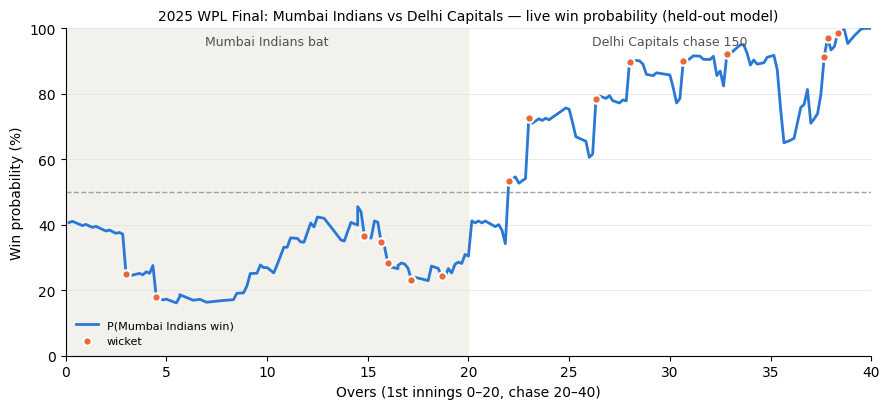

Mumbai Indians at their lowest: 16% in over 5.5 of their innings.
Start of the chase: Delhi Capitals favoured at 59%. Mumbai Indians moved ahead with Delhi Capitals 15/1 after 2.0 overs.


In [2]:
pred = pd.read_csv('reports/stage1/test_predictions.csv.gz', dtype={'match_id': str})
pred = pred[pred.match_id == MATCH].set_index(['innings', 'seq'])

rows = []                                            # one row per delivery: x position in overs, score, wickets
for k, inn in enumerate(match['innings'], start=1):
    legal = runs = wkts = 0
    for seq, d in enumerate((d for o in inn['overs'] for d in o['deliveries']), start=1):
        legal += 'wides' not in d.get('extras', {}) and 'noballs' not in d.get('extras', {})
        runs += d['runs']['total']
        out = [w for w in d.get('wickets', []) if w['kind'] not in ('retired hurt', 'retired not out')]
        wkts += len(out)
        rows.append({'innings': k, 'seq': seq, 'x': 20 * (k - 1) + legal / 6, 'runs': runs, 'wkts': wkts,
                     'wicket': bool(out), 'p': pred.loc[(k, seq), 'parscore']})
b = pd.DataFrame(rows)
bat1, bat2 = match['innings'][0]['team'], match['innings'][1]['team']
print(f"{bat1} {b[b.innings == 1].runs.max()}/{b[b.innings == 1].wkts.max()}  vs  "
      f"{bat2} {b[b.innings == 2].runs.max()}/{b[b.innings == 2].wkts.max()}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axvspan(0, 20, color='#f2f1ec', zorder=0)
ax.axhline(50, color='#a3a29b', lw=1, ls='--', zorder=1)
ax.plot(b.x, 100 * b.p, color='#2a78d6', lw=2, zorder=2, label=f'P({bat1} win)')
w = b[b.wicket]
ax.scatter(w.x, 100 * w.p, s=36, color='#eb6834', edgecolor='white', linewidth=1.5, zorder=3, label='wicket')
ax.set(xlim=(0, 40), ylim=(0, 100), xlabel='Overs (1st innings 0–20, chase 20–40)', ylabel='Win probability (%)')
ax.set_xticks(range(0, 41, 5))
ax.text(10, 95, f'{bat1} bat', ha='center', color='#52514e', fontsize=9)
ax.text(30, 95, f'{bat2} chase {match["innings"][1]["target"]["runs"]}', ha='center', color='#52514e', fontsize=9)
ax.set_title(f'2025 WPL Final: {bat1} vs {bat2} — live win probability (held-out model)', fontsize=10)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e6e5e0', lw=0.6)
ax.legend(frameon=False, loc='lower left', fontsize=8)
fig.tight_layout()
os.makedirs('docs/img', exist_ok=True)
fig.savefig('docs/img/wpl2025_final_live_wp.png', dpi=160)
plt.show()

low = b.loc[b.p.idxmin()]
start = b[b.innings == 2].iloc[0]
flip = b[(b.innings == 2) & (b.p >= 0.5)].iloc[0]
print(f"{bat1} at their lowest: {100 * low.p:.0f}% in over {low.x:.1f} of {'their innings' if low.innings == 1 else 'the chase'}.")
print(f"Start of the chase: {bat2} favoured at {100 * (1 - start.p):.0f}%. {bat1} moved ahead with {bat2} "
      f"{flip.runs:.0f}/{flip.wkts:.0f} after {flip.x - 20:.1f} overs.")

### Try a match state yourself

This calls the same function the API uses (`wpl.serving.predict_live`) with the **deployed** model, which is
fitted on all seasons. Send the ball history of the current innings: total runs off each delivery, whether it was
legal, and wickets on it.

In [3]:
live = load_bundle('models/live_v1.json')
# A chase of 150: 5 overs gone, 40 scored for 1 wicket (8 an over; the last ball is a wicket).
balls = [{'runs': r, 'legal': True, 'wickets': w} for r, w in
         [(1, 0), (0, 0), (4, 0), (0, 0), (1, 0), (2, 0)] * 5]
balls[-1]['wickets'] = 1
out = predict_live(live, innings=2, deliveries=balls, max_balls=120, target=150)
s = out['state']
print(f"Chasing 150: {s['cum_runs']:.0f}/{s['cum_wickets']:.0f} after {s['legal_balls'] // 6:.0f} overs, "
      f"need {s['runs_needed']:.0f} at {s['required_rr']:.2f} an over")
print(f"P(chasing team wins) = {100 * (1 - out['bat_first_win_prob']):.1f}%")

Chasing 150: 40/1 after 5 overs, need 110 at 7.33 an over
P(chasing team wins) = 72.2%


## 2. Pre-match: why the API serves the base rate

After the toss, before ball 1. Stage 3 tested, under a rule fixed in advance, whether player-rating features beat
the simplest possible forecast — the share of WPL matches won by the team batting first. They did not, so that
base rate is what the API serves, and its response says so.

In [4]:
pm = load_bundle('models/prematch_v3.json')
d = pm['decision']
print(f"Served: P(team batting first wins) = {100 * pm['p_base']:.1f}%  ({pm['n_matches']} WPL matches)")
print(f"XI-strength model vs base rate, log-loss on 66 held-out matches: {d['delta']:+.3f} "
      f"[{d['ci_low']:+.3f}, {d['ci_high']:+.3f}] -> deploy only if the whole interval is below 0 -> {d['serve']}")

Served: P(team batting first wins) = 39.8%  (88 WPL matches)
XI-strength model vs base rate, log-loss on 66 held-out matches: +0.087 [+0.012, +0.162] -> deploy only if the whole interval is below 0 -> base_rate


## 3. XI strength: the two finalists

Each player has empirical-Bayes ratings for batting runs, dismissals, runs conceded and wickets per ball, estimated
from 799,502 deliveries of women's T20 cricket and adjusted for match situation, venue and opponent. A team's value
is in runs: expected runs from its batting order plus runs saved by its bowling, against an average side.

**Note:** these are the **latest** ratings (as of the end of the data), used here to illustrate the endpoint, not
the ratings the model had before this match. The as-of ratings used in the evaluation never see the future.

In [5]:
ratings = load_bundle('models/ratings_v3.json')
reg = info['registry']['people']
xis = {team: [reg[name] for name in names] for team, names in info['players'].items()}
res = predict_xi_strength(ratings, xis[bat1], xis[bat2], allow_unknown=True)
print(f"Ratings as of {ratings['as_of']} ({len(ratings['players']):,} players); unrated players: {res['unknown_players'] or 'none'}")
table = pd.DataFrame({bat1: res['bat_first'], bat2: res['chase']}).T[['bat_value', 'bowl_value', 'strength', 'strength_sd', 'coverage']]
print(table.round(1).to_string())
print(f"\nXI margin ({bat1} - {bat2}): {res['xi_margin']:+.1f} runs (sd {res['xi_margin_sd']:.1f})")

F = ratings['fields']
def top(team, field, n=3, best='high'):
    vals = [(ratings['players'][p][0], ratings['players'][p][F.index(field)]) for p in xis[team] if p in ratings['players']]
    vals = [v for v in vals if v[1] is not None]
    return sorted(vals, key=lambda v: v[1], reverse=(best == 'high'))[:n]
for team in (bat1, bat2):
    bats = ', '.join(f'{n} ({120 * v:+.1f})' for n, v in top(team, 'bat_runs'))
    bowls = ', '.join(f'{n} ({120 * v:+.1f})' for n, v in top(team, 'bowl_runs', best='low'))
    print(f"{team}: best batters (runs per 120 balls above par) {bats}\n    best economy (runs conceded per 120 balls vs par) {bowls}")

Ratings as of 2026-10-24 (3,418 players); unrated players: none
                bat_value  bowl_value  strength  strength_sd  coverage
Mumbai Indians        0.2         1.2       1.5          6.8       1.0
Delhi Capitals        9.5         8.3      17.8          5.9       1.0

XI margin (Mumbai Indians - Delhi Capitals): -16.4 runs (sd 9.0)
Mumbai Indians: best batters (runs per 120 balls above par) NR Sciver-Brunt (+18.6), HK Matthews (+15.8), H Kaur (+9.3)
    best economy (runs conceded per 120 balls vs par) S Ismail (-14.4), S Gupta (-9.4), AC Kerr (-5.3)
Delhi Capitals: best batters (runs per 120 balls above par) Shafali Verma (+40.4), SJ Bryce (+16.1), JI Rodrigues (+13.4)
    best economy (runs conceded per 120 balls vs par) M Kapp (-20.6), NS Prasad (-13.2), Shafali Verma (-10.4)


## Read more

- [Model card: pre-match v3](../docs/stage3/MODEL_CARD_prematch_v3.md) — the evaluation, the verdict, its limits.
- [Ratings specification](../docs/stage3/RATINGS_SPEC.md) and [pre-registration](../docs/stage3/PREREG_stage3.md).
- [Stage 1 results](../reports/stage1/results.md) — the live models and the audit of the first version.
- [Technical report (PDF)](../paper/wpl_stage1-3_report.pdf).